# TP III (TERCERO) DE FEDE 6


In [ ]:
import torch 
import scipy 
import time
import matplotlib.pyplot as plt
import numpy as np
import cv2
import torchvision.transforms as transforms 
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import os
import pandas as pd
import torch.optim as optim
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import classification_report, ConfusionMatrixDisplay 
from sklearn.manifold import TSNE

In [2]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

In [3]:
class CNNPropia(nn.Module):
    def __init__(self, c1 = 16, c2 = 32, hidden = 128):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels = 3,
                               out_channels = c1,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)

        self.pool1 = nn.MaxPool2d(kernel_size = 2, stride = 2)

        self.conv2 = nn.Conv2d(in_channels = c1,
                               out_channels = c2,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)

        self.pool2 = nn.MaxPool2d(kernel_size = 2, stride = 2)

        self.fc1 = nn.Linear(c2 * 16 * 16, hidden)
        self.fc2 = nn.Linear(hidden, 10)

    def forward(self, x):
        x = F.leaky_relu(self.conv1(x))
        x = self.pool1(x)

        x = F.leaky_relu(self.conv2(x))
        x = self.pool2(x)

        x = torch.flatten(x, 1)

        x = F.leaky_relu(self.fc1(x))
        x = self.fc2(x)

        return x


In [4]:
class EuroSATDataset(Dataset):
    def __init__(self, csv_path, img_dir, transform=None):
        self.df = pd.read_csv(csv_path)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fila = self.df.iloc[idx]
        ruta = os.path.join(self.img_dir, fila["Filename"])  
        img = Image.open(ruta).convert("RGB")
        label = int(fila["Label"])                            
        if self.transform:
            img = self.transform(img)
        return img, label

In [5]:
batch_size = 32
MEAN = [0.3502, 0.3842, 0.4176]   # calculados con 3000 imágenes de train. 3 valores -> R, G, B
STD  = [0.2034, 0.1363, 0.1153]

class RandomRotation90:
    def __call__(self, img):
        k = int(torch.randint(0, 4, (1,)))
        return TF.rotate(img, 90 * k)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    RandomRotation90(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform = transforms.Compose([   
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = EuroSATDataset("./archive/train.csv", "./archive", train_transform)
val_ds   = EuroSATDataset("./archive/validation.csv", "./archive", val_transform)
test_ds  = EuroSATDataset("./archive/test.csv", "./archive", val_transform)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0)


Epoch 1 finished. Train accuracy: 53.70%. Validation accuracy: 64.43%.
Epoch 2 finished. Train accuracy: 71.41%. Validation accuracy: 76.48%.
Epoch 3 finished. Train accuracy: 76.26%. Validation accuracy: 77.26%.
Epoch 4 finished. Train accuracy: 78.74%. Validation accuracy: 76.31%.
Epoch 5 finished. Train accuracy: 81.67%. Validation accuracy: 83.30%.
Epoch 6 finished. Train accuracy: 82.94%. Validation accuracy: 83.52%.
Epoch 7 finished. Train accuracy: 84.72%. Validation accuracy: 82.72%.
Epoch 8 finished. Train accuracy: 85.38%. Validation accuracy: 80.69%.
Epoch 9 finished. Train accuracy: 86.75%. Validation accuracy: 86.09%.
Epoch 10 finished. Train accuracy: 87.23%. Validation accuracy: 84.09%.
Epoch 11 finished. Train accuracy: 87.05%. Validation accuracy: 87.39%.
Epoch 12 finished. Train accuracy: 89.23%. Validation accuracy: 85.72%.
Epoch 13 finished. Train accuracy: 89.52%. Validation accuracy: 85.74%.
Epoch 14 finished. Train accuracy: 89.79%. Validation accuracy: 84.17%.
E

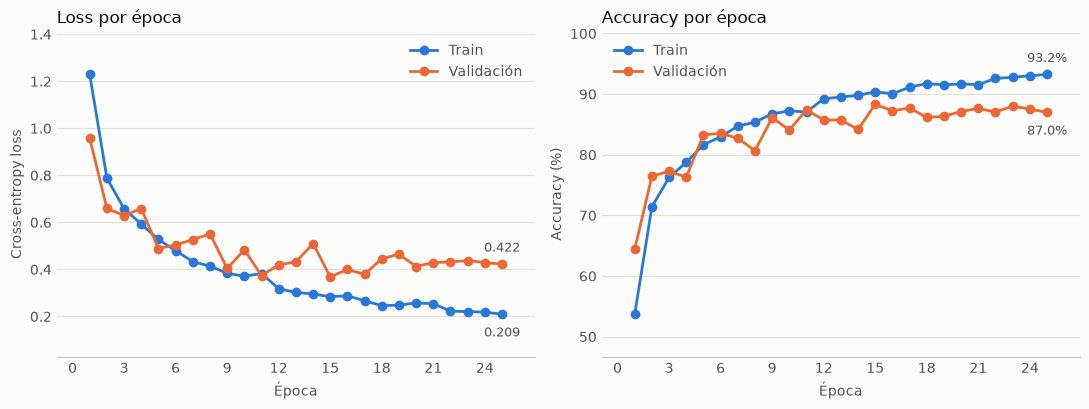

In [11]:
torch.manual_seed(67)
nuestraNN = CNNPropia()
nuestraNN.to(device)
learning_rate = 0.01
momentum = 0.9

epocas_monitoreo = 3
cada_n_batches = 20
capas = {"conv1": nuestraNN.conv1, "conv2": nuestraNN.conv2,
         "fc1": nuestraNN.fc1, "fc2": nuestraNN.fc2}
grad_norms = {nombre: [] for nombre in capas}
batches_monitoreados = []

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(nuestraNN.parameters(), lr = learning_rate, momentum = momentum)

epochs = 25
train_losses, val_losses, train_accs, val_accs = [], [], [], []
cnn_times = []

for epoch in range(epochs): 
    t0 = time.time()
    running_loss = 0.0
    train_correct = 0
    total = 0
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        outputs = nuestraNN(inputs)
        loss = criterion(outputs, labels)
        loss.backward()

        if epoch < epocas_monitoreo and i % cada_n_batches == 0:
            batches_monitoreados.append(epoch * len(train_loader) + i)
            for nombre, capa in capas.items():
                grad_norms[nombre].append(capa.weight.grad.norm().item()) 
        
        optimizer.step()

        running_loss += loss.item() * inputs.shape[0]

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_accuracy = 100 * train_correct / total
    running_loss = running_loss/total

    val_correct = 0
    total = 0
    val_loss = 0
    with torch.no_grad():
        for data in val_loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = nuestraNN(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
            val_loss += criterion(outputs, labels).item() * images.shape[0]

    val_accuracy = 100 * val_correct / total
    val_loss = val_loss / total
    cnn_times.append(time.time()-t0)
    train_losses.append(running_loss)
    val_losses.append(val_loss)
    train_accs.append(train_accuracy)
    val_accs.append(val_accuracy)
    print(f'Epoch {epoch + 1} finished. Train accuracy: {train_accuracy:.2f}%. Validation accuracy: {val_accuracy:.2f}%.')

print('Finished training.')




# Graficos Actualizacion de Acc y Loss por epoch
COLOR_TRAIN, COLOR_VAL = "#2a78d6", "#eb6834"
TINTA, GRILLA, EJE = "#52514e", "#e1e0d9", "#c3c2b7"
epocas = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor="#fcfcfb")
paneles = [
    (axes[0], train_losses, val_losses, "Loss por época", "Cross-entropy loss", "{:.3f}"),
    (axes[1], train_accs, val_accs, "Accuracy por época", "Accuracy (%)", "{:.1f}%"),
]

for ax, train, val, titulo, ylabel, formato in paneles:
    ax.plot(epocas, train, color=COLOR_TRAIN, linewidth=2, marker="o", markersize=6, label="Train")
    ax.plot(epocas, val, color=COLOR_VAL, linewidth=2, marker="o", markersize=6, label="Validación")


    for serie, otra in [(train, val), (val, train)]:
        ax.annotate(formato.format(serie[-1]), (epocas[-1], serie[-1]),
                    xytext=(0, 9 if serie[-1] >= otra[-1] else -16), textcoords="offset points",
                    ha="center", fontsize=9, color=TINTA)

    ax.set_title(titulo, loc="left", fontsize=12, color="#0b0b0b")
    ax.set_xlabel("Época", color=TINTA)
    ax.set_ylabel(ylabel, color=TINTA)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.margins(x=0.08, y=0.18)
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TINTA, length=0)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(EJE)
    ax.legend(frameon=False, labelcolor=TINTA)

fig.tight_layout()
plt.show()

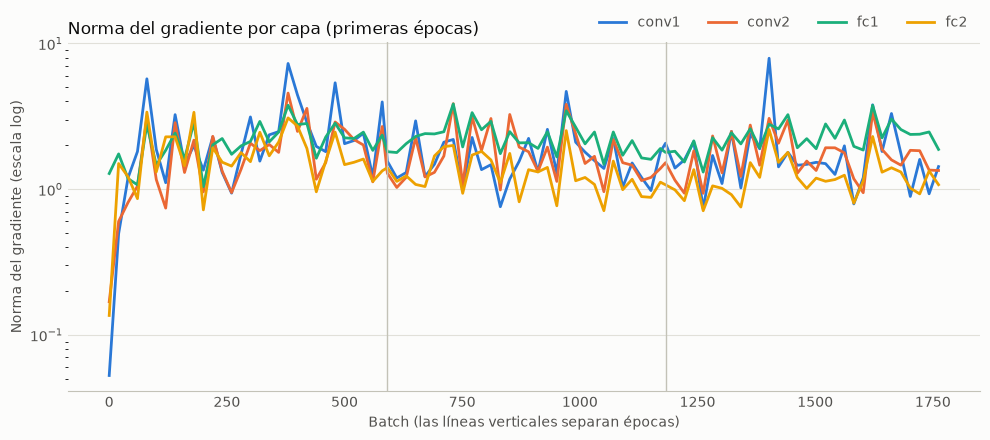

In [12]:
# Grafico para ver como evoluciona el Grad por epoch
clases = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
          'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
COLORES = {"conv1": "#2a78d6", "conv2": "#eb6834", "fc1": "#1baf7a", "fc2": "#eda100"}

fig, ax = plt.subplots(figsize=(10, 4.5), facecolor="#fcfcfb")
for nombre, valores in grad_norms.items():
    ax.plot(batches_monitoreados, valores, color=COLORES[nombre], linewidth=2, label=nombre)

for epoca in range(1, epocas_monitoreo):
    ax.axvline(epoca * len(train_loader), color=EJE, linewidth=1)

ax.set_yscale("log")
ax.set_title("Norma del gradiente por capa (primeras épocas)", loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Batch (las líneas verticales separan épocas)", color=TINTA)
ax.set_ylabel("Norma del gradiente (escala log)", color=TINTA)
ax.set_facecolor("#fcfcfb")
ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TINTA, length=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(EJE)
ax.legend(frameon=False, labelcolor=TINTA, ncol=4, loc="lower right", bbox_to_anchor=(1, 1))

fig.tight_layout()
plt.show()


In [13]:
def evaluar(model, dataloader, criterion = None, device = device, label_offset = 0):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device) - label_offset

            outputs = model(images)

            if criterion is not None:
                running_loss += criterion(outputs, labels).item() * images.shape[0]

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = running_loss / total if criterion is not None else None
    accuracy = 100 * correct / total

    return avg_loss, accuracy


In [14]:
criterion = nn.CrossEntropyLoss()
test_loss, test_accuracy = evaluar(nuestraNN, test_loader, criterion)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.2f}%')

Test loss: 0.4155
Test accuracy: 87.37%


In [15]:
def obtener_predicciones(model, dataloader):
    model.eval()

    with torch.no_grad():
        etiquetas = []
        predicciones = []
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
    
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            etiquetas.append(labels.cpu())
            predicciones.append(predicted.cpu())

    return torch.cat(etiquetas).numpy(), torch.cat(predicciones).numpy()

y_true, y_pred = obtener_predicciones(nuestraNN, test_loader)
print(classification_report(y_true, y_pred, target_names=['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']))


                      precision    recall  f1-score   support

          AnnualCrop       0.90      0.89      0.90       300
              Forest       0.95      0.98      0.97       300
HerbaceousVegetation       0.80      0.82      0.81       300
             Highway       0.81      0.76      0.79       250
          Industrial       0.94      0.88      0.91       250
             Pasture       0.80      0.90      0.84       200
       PermanentCrop       0.89      0.60      0.72       250
         Residential       0.96      0.97      0.97       300
               River       0.71      0.91      0.80       250
             SeaLake       0.96      0.98      0.97       300

            accuracy                           0.87      2700
           macro avg       0.87      0.87      0.87      2700
        weighted avg       0.88      0.87      0.87      2700



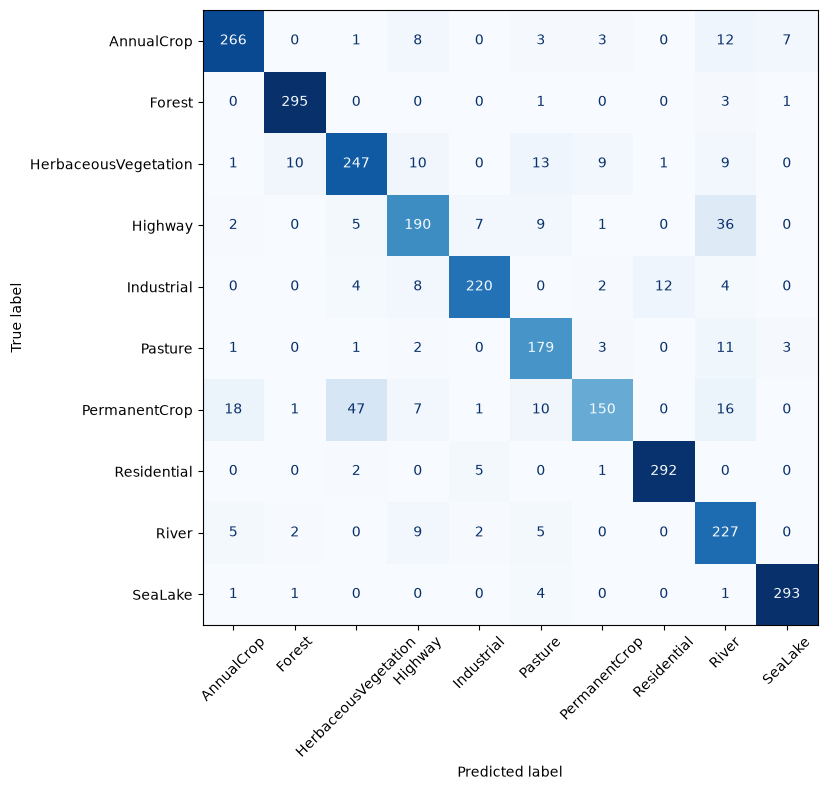

In [16]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=clases,
                                        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
fig.tight_layout()
fig.savefig("matriz_confusion.png", dpi=150)
plt.show()

In [17]:
torch.save(nuestraNN.state_dict(), "cnn_propia.pt")

def obtener_features(model, dataloader):
    activaciones, etiquetas = [], []

    def hook(module, input, output):
        activaciones.append(input[0].detach().cpu())

    handle = model.fc2.register_forward_hook(hook)

    model.eval()
    with torch.no_grad():
        for images, labels in dataloader:
            model(images.to(device))
            etiquetas.append(labels)

    handle.remove()

    return torch.cat(activaciones).numpy(), torch.cat(etiquetas).numpy()

X, y = obtener_features(nuestraNN, test_loader)

X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=67).fit_transform(X)

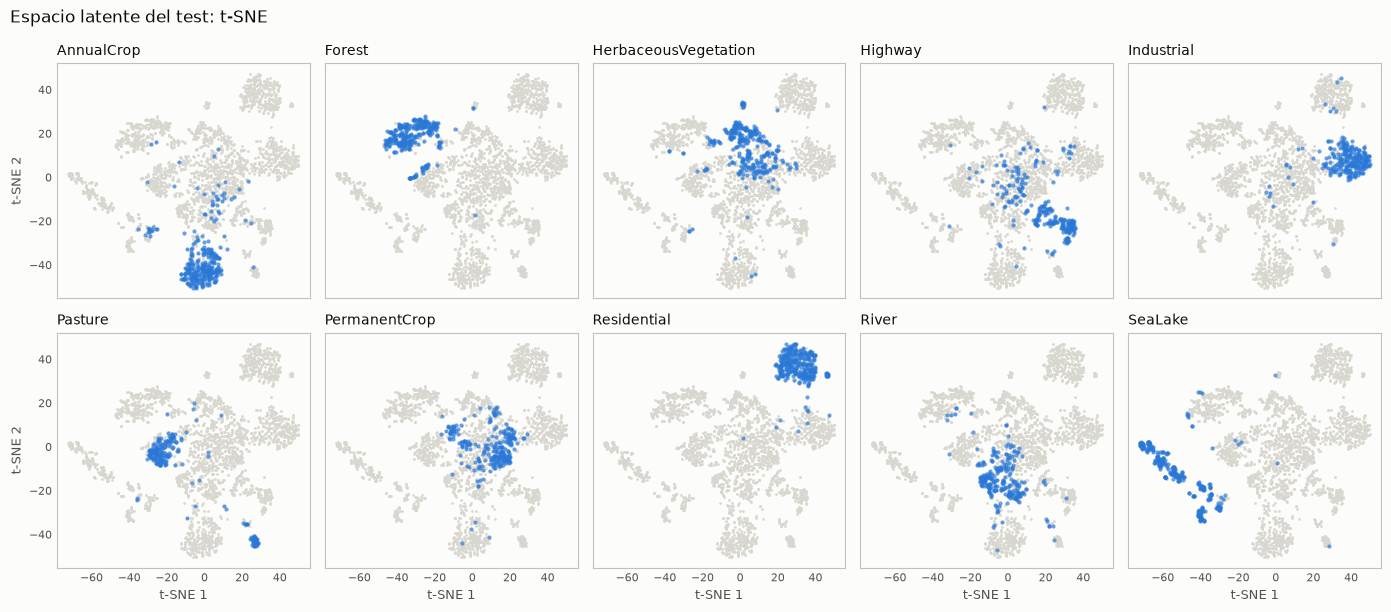

In [18]:
clases = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
          'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

def graficar_espacio_latente(coords, y, clases, titulo, xlabel, ylabel, archivo):
    COLOR_CLASE, COLOR_RESTO = "#2a78d6", "#d8d7cf"
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.2), sharex=True, sharey=True, facecolor="#fcfcfb")

    for i, (ax, clase) in enumerate(zip(axes.flat, clases)):
        es_clase = y == i
        ax.scatter(coords[~es_clase, 0], coords[~es_clase, 1], s=4, color=COLOR_RESTO, linewidths=0)
        ax.scatter(coords[es_clase, 0], coords[es_clase, 1], s=9, color=COLOR_CLASE, alpha=0.7, linewidths=0)
        ax.set_title(clase, loc="left", fontsize=10, color="#0b0b0b")
        ax.set_facecolor("#fcfcfb")
        ax.tick_params(colors=TINTA, length=0, labelsize=8)
        for lado in ax.spines.values():
            lado.set_color(EJE)

    for ax in axes[1]:
        ax.set_xlabel(xlabel, color=TINTA, fontsize=9)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel, color=TINTA, fontsize=9)

    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, color="#0b0b0b")
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, facecolor=fig.get_facecolor())
    plt.show()

graficar_espacio_latente(X_tsne, y, clases, "Espacio latente del test: t-SNE",
                         "t-SNE 1", "t-SNE 2", "latente_tsne.png")

Sí se forman clusters, aunque no para todas las clases:

Bien definidas: Residential, Industrial, SeaLake, Forest y AnnualCrop.
Mezcladas: PermanentCrop se pega a HerbaceousVegetation, y Highway y River quedan juntas y dispersas en la zona central. Son las mismas confusiones de la matriz, lo que indica que los errores ya vienen del espacio latente y no solo de la capa final.
Más de un grupo: Pasture tiene una isla aparte cerca de (33, -27), y Forest y AnnualCrop también tienen grupos chicos separados. Podrían ser subtipos visuales dentro de la clase, pero habría que mirar esas imágenes para afirmarlo.

## 3.

In [ ]:
IMN_MEAN, IMN_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

tl_train_tf = transforms.Compose([
    transforms.Resize(128),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    RandomRotation90(),
    transforms.ToTensor(), transforms.Normalize(IMN_MEAN, IMN_STD),
])
tl_eval_tf = transforms.Compose([
    transforms.Resize(128),
    transforms.ToTensor(), transforms.Normalize(IMN_MEAN, IMN_STD),
])

tl_train = EuroSATDataset("./archive/train.csv", "./archive", tl_train_tf)
tl_val   = EuroSATDataset("./archive/validation.csv", "./archive", tl_eval_tf)
tl_test  = EuroSATDataset("./archive/test.csv", "./archive", tl_eval_tf)
tl_train_loader = DataLoader(tl_train, batch_size=32, shuffle=True)
tl_val_loader   = DataLoader(tl_val, batch_size=32)
tl_test_loader  = DataLoader(tl_test, batch_size=32)


resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in resnet.parameters():
    p.requires_grad = False
resnet.fc = nn.Linear(resnet.fc.in_features, 10)   
# fine tuning parcial
for p in resnet.layer4.parameters():
    p.requires_grad = True
resnet.to(device)

params = [p for p in resnet.parameters() if p.requires_grad]
optimizer = optim.Adam(params, lr=1e-3)
criterion = nn.CrossEntropyLoss()

tl_train_losses, tl_val_losses, tl_train_accs, tl_val_accs, tl_times = [], [], [], [], []
for epoch in range(10):
    t0 = time.time()
    resnet.train()
    loss_sum, correct, total = 0, 0, 0
    for x, y in tl_train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = resnet(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    tl_train_losses.append(loss_sum / total)
    tl_train_accs.append(100 * correct / total)

    v_loss, v_acc = evaluar(resnet, tl_val_loader, criterion)
    tl_val_losses.append(v_loss); tl_val_accs.append(v_acc)
    tl_times.append(time.time() - t0)
    print(f"Epoch {epoch+1}: train {tl_train_accs[-1]:.2f}% | val {v_acc:.2f}% | {tl_times[-1]:.1f}s")

test_loss, test_acc = evaluar(resnet, tl_test_loader, criterion)
y_true, y_pred = obtener_predicciones(resnet, tl_test_loader)
print(classification_report(y_true, y_pred, target_names=clases))

Epoch 1: train 90.71% | val 94.98% | 56.6s
Epoch 2: train 94.03% | val 95.61% | 48.7s
Epoch 3: train 94.87% | val 96.37% | 47.0s
Epoch 4: train 95.52% | val 97.04% | 46.8s
Epoch 5: train 96.18% | val 97.24% | 48.1s
Epoch 6: train 96.47% | val 96.57% | 47.0s
Epoch 7: train 96.62% | val 96.83% | 46.8s
Epoch 8: train 96.68% | val 97.69% | 47.0s
Epoch 9: train 96.97% | val 97.24% | 46.9s
Epoch 10: train 97.23% | val 95.98% | 46.8s
                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.94      0.96       300
              Forest       0.95      0.99      0.97       300
HerbaceousVegetation       0.97      0.96      0.96       300
             Highway       0.99      0.91      0.95       250
          Industrial       0.98      0.99      0.98       250
             Pasture       0.97      0.96      0.97       200
       PermanentCrop       0.91      0.95      0.93       250
         Residential       1.00      0.99      1.00       300
          

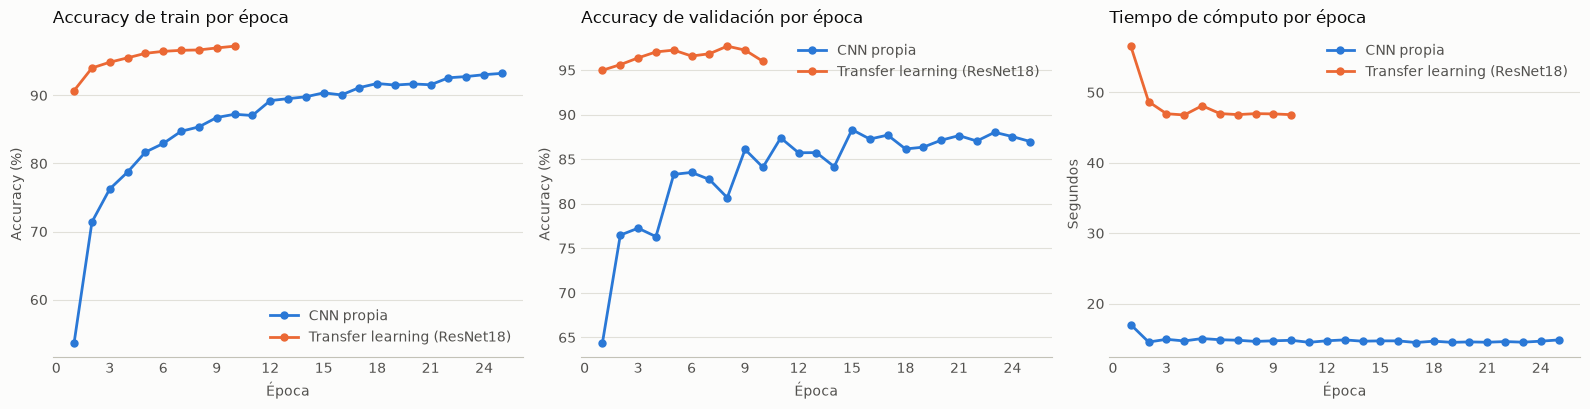

In [20]:
COLOR_CNN, COLOR_TL = "#2a78d6", "#eb6834"

def plot_comparacion(cnn_train, cnn_val, cnn_times, tl_train, tl_val, tl_times):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), facecolor="#fcfcfb")
    paneles = [
        (axes[0], cnn_train, tl_train, "Accuracy de train por época", "Accuracy (%)"),
        (axes[1], cnn_val,   tl_val,   "Accuracy de validación por época", "Accuracy (%)"),
        (axes[2], cnn_times, tl_times, "Tiempo de cómputo por época", "Segundos"),
    ]
    for ax, cnn, tl, titulo, ylabel in paneles:
        ax.plot(range(1, len(cnn) + 1), cnn, color=COLOR_CNN, linewidth=2,
                marker="o", markersize=5, label="CNN propia")
        ax.plot(range(1, len(tl) + 1), tl, color=COLOR_TL, linewidth=2,
                marker="o", markersize=5, label="Transfer learning (ResNet18)")
        ax.set_title(titulo, loc="left", fontsize=12, color="#0b0b0b")
        ax.set_xlabel("Época", color=TINTA)
        ax.set_ylabel(ylabel, color=TINTA)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_facecolor("#fcfcfb")
        ax.grid(axis="y", color=GRILLA, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TINTA, length=0)
        for lado in ["top", "right", "left"]:
            ax.spines[lado].set_visible(False)
        ax.spines["bottom"].set_color(EJE)
        ax.legend(frameon=False, labelcolor=TINTA)
    fig.tight_layout()
    fig.savefig("comparacion_cnn_vs_tl.png", dpi=150, facecolor=fig.get_facecolor())
    plt.show()

plot_comparacion(train_accs, val_accs, cnn_times,
                 tl_train_accs, tl_val_accs, tl_times)